# Análise exploratória: Olist

Análises feitas sobre a camada **gold** do Data Warehouse (DuckDB), gerada pelo pipeline em `src/pipeline.py`.

Foi escolhida uma pergunta de cada tópico do desafio. Os estados da **Região Norte** aparecem destacados em laranja nos gráficos por estado.

In [14]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

con = duckdb.connect("../data/olist.duckdb", read_only=True)

IMG_DIR = Path("../docs/img")
IMG_DIR.mkdir(parents=True, exist_ok=True)

COR = "#1f4e79"
COR_DESTAQUE = "#e07b00"
COR_SECUNDARIA = "#6b6b6b"
ESTADOS_NORTE = {"AC", "AM", "AP", "PA", "RO", "RR", "TO"}
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
FONTE = "Fonte: Olist (Kaggle), camada gold do DW."

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.3,
})

def q(sql: str) -> pd.DataFrame:
    """Executa uma consulta no DW e devolve um DataFrame."""
    return con.sql(sql).df()

def br(valor: float, casas: int = 1) -> str:
    """Formata um número no padrão brasileiro: 1.234,5."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def titulo(ax, insight: str, contexto: str) -> None:
    """Título com o insight do gráfico e subtítulo com métrica, unidade e período."""
    ax.set_title(insight, loc="left", fontsize=13, fontweight="bold", pad=24, parse_math=False)
    ax.text(0, 1.02, contexto, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=9.5, color=COR_SECUNDARIA, parse_math=False)

def rodape(fig, nota: str = "") -> None:
    """Fonte dos dados e observações sobre a métrica, no rodapé da figura."""
    fig.text(0.01, -0.03, f"{FONTE} {nota}".strip(), ha="left", va="top",
             fontsize=8, color=COR_SECUNDARIA, wrap=True)


def salvar(fig, nome: str) -> None:
    """Salva o gráfico em docs/img para uso no README."""
    fig.savefig(IMG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")

## Tópico 1: Vendas
**Pergunta (b): como a receita total varia mês a mês?**

- Receita = soma do `price` dos itens (sem frete), apenas de pedidos não cancelados e não indisponíveis.
- Período: jan/2017 a ago/2018. Os meses anteriores e posteriores têm coleta incompleta (regra #10 do perfilamento).

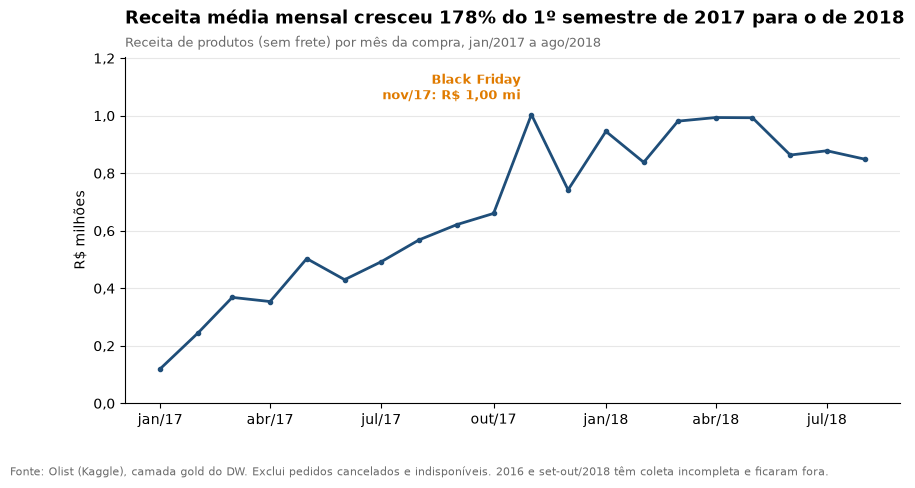

,mes,receita_mi
0,2017-01-01,0.120098
1,2017-02-01,0.244959
2,2017-03-01,0.368341
3,2017-04-01,0.353843
4,2017-05-01,0.503159
5,2017-06-01,0.429917
6,2017-07-01,0.492287
7,2017-08-01,0.568246
8,2017-09-01,0.621416
9,2017-10-01,0.660180


In [15]:
receita_mensal = q("""
SELECT order_month AS mes, sum(price) AS receita
FROM gold.fact_order_items
WHERE is_valid_sale
  AND order_month BETWEEN DATE '2017-01-01' AND DATE '2018-08-01'
GROUP BY 1
ORDER BY 1
""")
receita_mensal["mes"] = pd.to_datetime(receita_mensal["mes"])
receita_mensal["receita_mi"] = receita_mensal["receita"].astype(float) / 1e6

# Insight do título: média mensal do 1º semestre de 2017 contra a do 1º semestre de 2018
s1_2017 = receita_mensal.loc[receita_mensal["mes"].between("2017-01-01", "2017-06-01"), "receita_mi"].mean()
s1_2018 = receita_mensal.loc[receita_mensal["mes"].between("2018-01-01", "2018-06-01"), "receita_mi"].mean()
crescimento = (s1_2018 / s1_2017 - 1) * 100

pico = receita_mensal.loc[receita_mensal["receita_mi"].idxmax()]
rotulo_pico = f"{MESES[pico['mes'].month - 1]}/{pico['mes']:%y}: R$ {br(pico['receita_mi'], 2)} mi"
if pico["mes"].month == 11:
    rotulo_pico = f"Black Friday\n{rotulo_pico}"

fig, ax = plt.subplots()
ax.plot(receita_mensal["mes"], receita_mensal["receita_mi"], color=COR, linewidth=2, marker="o", markersize=3)
ax.annotate(rotulo_pico, xy=(pico["mes"], pico["receita_mi"]), xytext=(-8, 8),
            textcoords="offset points", ha="right", va="bottom",
            color=COR_DESTAQUE, fontweight="bold", fontsize=9)

ticks = receita_mensal["mes"].iloc[::3]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{MESES[d.month - 1]}/{d:%y}" for d in ticks])
ax.set_ylim(0, receita_mensal["receita_mi"].max() * 1.2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1)))
ax.set_ylabel("R$ milhões")

titulo(ax,
       f"Receita média mensal cresceu {br(crescimento, 0)}% do 1º semestre de 2017 para o de 2018",
       "Receita de produtos (sem frete) por mês da compra, jan/2017 a ago/2018")
rodape(fig, "Exclui pedidos cancelados e indisponíveis. 2016 e set-out/2018 têm coleta incompleta e ficaram fora.")
salvar(fig, "t1_receita_mensal")
plt.show()

receita_mensal[["mes", "receita_mi"]]

**Conclusão:** a receita de produtos (sem frete) cresceu 178% entre o 1º semestre de 2017 e o de 2018, com pico de R$ 1,0 mi em novembro de 2017, 52% acima de outubro, efeito da Black Friday. Em 2018 a receita se estabilizou perto de R$ 0,9 mi por mês e recuou levemente a partir de junho, um sinal de que o crescimento acelerado de 2017 não se manteve e de que vale investigar as causas.

## Tópico 2: Logística
**Pergunta (a): qual o tempo médio de entrega, em dias, por estado?**

- Tempo de entrega = dias de calendário entre a compra e a entrega ao cliente (`delivery_days` da `fact_orders`).
- Apenas pedidos entregues com data de entrega registrada (regra #5).

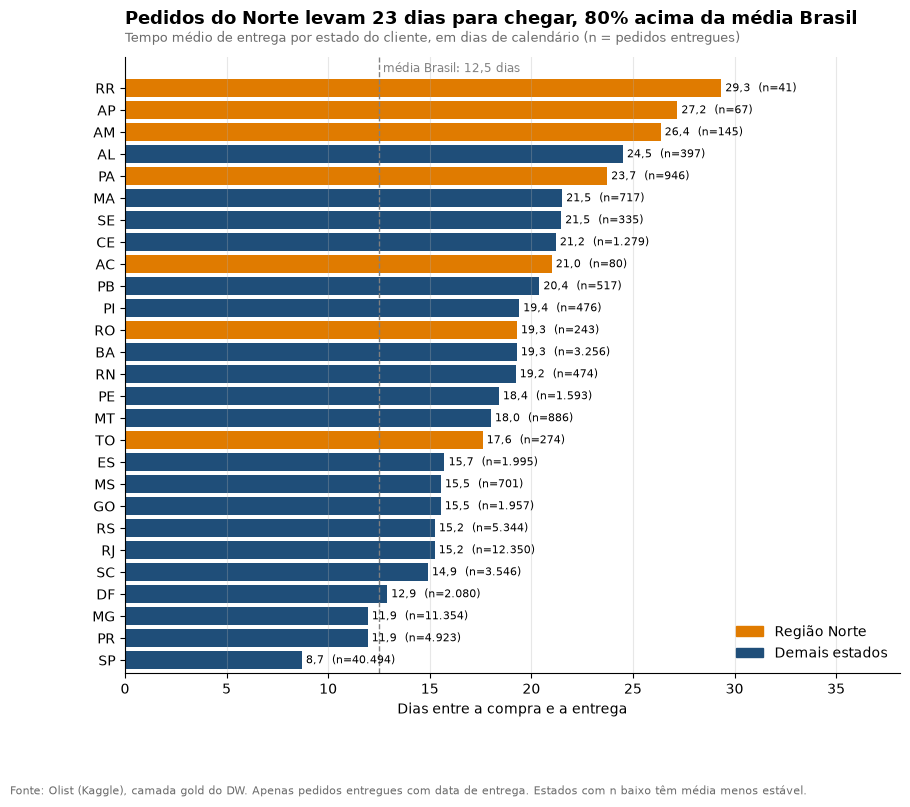

,uf,dias_medios,pedidos
26,RR,29.341463,41
25,AP,27.179104,67
24,AM,26.358621,145
23,AL,24.501259,397
22,PA,23.725159,946
21,MA,21.511855,717
20,SE,21.462687,335
19,CE,21.200156,1279
18,AC,21.000000,80
17,PB,20.388781,517


In [16]:
prazo_uf = q("""
SELECT customer_state AS uf, avg(delivery_days) AS dias_medios, count(*) AS pedidos
FROM gold.fact_orders
WHERE delivery_days IS NOT NULL
GROUP BY 1
ORDER BY dias_medios
""")
media_brasil = q("""
SELECT avg(delivery_days) AS media FROM gold.fact_orders WHERE delivery_days IS NOT NULL
""")["media"].iloc[0]

# Média do Norte ponderada pelo número de pedidos de cada estado
norte = prazo_uf[prazo_uf["uf"].isin(ESTADOS_NORTE)]
media_norte = (norte["dias_medios"] * norte["pedidos"]).sum() / norte["pedidos"].sum()
acima = (media_norte / media_brasil - 1) * 100

cores = [COR_DESTAQUE if uf in ESTADOS_NORTE else COR for uf in prazo_uf["uf"]]
rotulos = [f"{br(d)}  (n={br(n, 0)})" for d, n in zip(prazo_uf["dias_medios"], prazo_uf["pedidos"])]

fig, ax = plt.subplots(figsize=(10, 8))
barras = ax.barh(prazo_uf["uf"], prazo_uf["dias_medios"], color=cores)
ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
ax.axvline(media_brasil, color="gray", linestyle="--", linewidth=1)
ax.text(media_brasil, len(prazo_uf) - 0.4, f" média Brasil: {br(media_brasil)} dias",
        color="gray", fontsize=8.5, va="bottom")
ax.set_xlim(0, prazo_uf["dias_medios"].max() * 1.3)
ax.set_ylim(-0.6, len(prazo_uf) + 0.4)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("Dias entre a compra e a entrega")
ax.legend(handles=[Patch(color=COR_DESTAQUE, label="Região Norte"), Patch(color=COR, label="Demais estados")],
          loc="lower right", frameon=False)

titulo(ax,
       f"Pedidos do Norte levam {br(media_norte, 0)} dias para chegar, {br(acima, 0)}% acima da média Brasil",
       "Tempo médio de entrega por estado do cliente, em dias de calendário (n = pedidos entregues)")
rodape(fig, "Apenas pedidos entregues com data de entrega. Estados com n baixo têm média menos estável.")
salvar(fig, "t2_prazo_por_estado")
plt.show()

prazo_uf.sort_values("dias_medios", ascending=False)

**Conclusão:** o prazo de entrega cresce com a distância de São Paulo, que concentra os vendedores: vai de 8,7 dias em SP a 29,3 dias em RR, mais de três vezes. Os três estados mais lentos são do Norte (RR, AP e AM), e a região tem poucos pedidos (41 em RR, 67 em AP), o que sugere uma demanda reprimida pelo prazo. Vendedores ou estoques regionais poderiam reduzir essa diferença.

## Tópico 3: Satisfação do cliente
**Pergunta (b): pedidos atrasados têm nota média menor que os entregues no prazo?**

- Atrasado = entregue depois da data estimada (`is_late` da `fact_orders`).
- Uma avaliação por pedido, a mais recente (regra #1), para que nenhum pedido pese duas vezes na média.

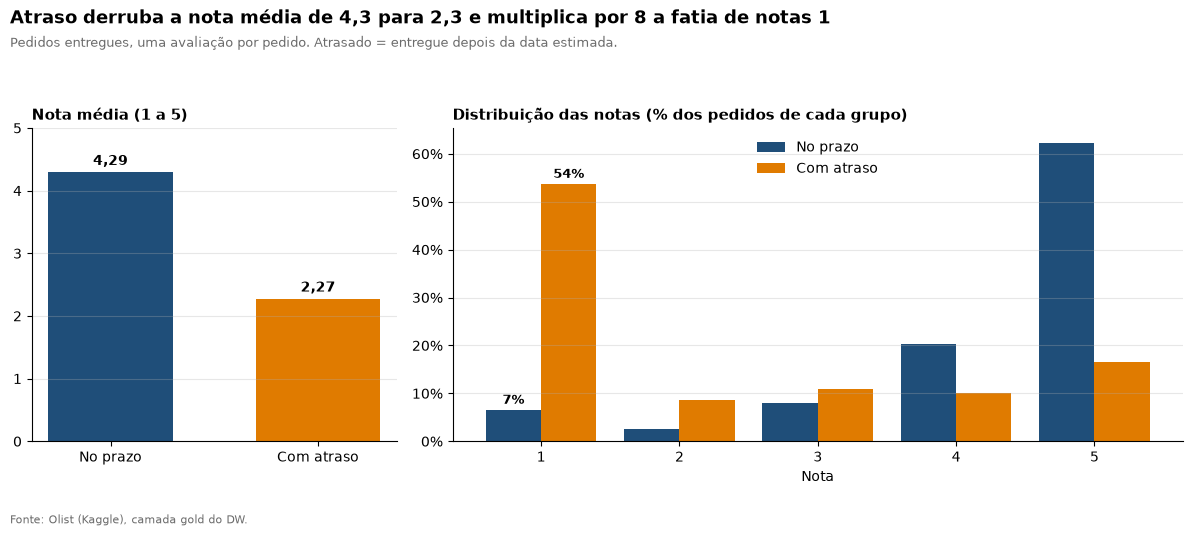

,situacao,nota_media,pedidos
0,No prazo,4.290386,89443
1,Com atraso,2.270491,6381


In [17]:
media_nota = q("""
SELECT CASE WHEN is_late THEN 'Com atraso' ELSE 'No prazo' END AS situacao,
       avg(review_score) AS nota_media,
       count(*) AS pedidos
FROM gold.fact_orders
WHERE is_late IS NOT NULL AND review_score IS NOT NULL
GROUP BY 1
ORDER BY 1 DESC
""")
notas = q("""
SELECT CASE WHEN is_late THEN 'Com atraso' ELSE 'No prazo' END AS situacao,
       review_score AS nota,
       count(*) AS pedidos
FROM gold.fact_orders
WHERE is_late IS NOT NULL AND review_score IS NOT NULL
GROUP BY 1, 2
""")
dist = notas.pivot(index="nota", columns="situacao", values="pedidos")
dist = dist / dist.sum() * 100  # % dos pedidos de cada grupo

medias = media_nota.set_index("situacao")["nota_media"]
vezes_nota1 = dist.loc[1, "Com atraso"] / dist.loc[1, "No prazo"]
cores_situacao = {"No prazo": COR, "Com atraso": COR_DESTAQUE}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 2]})

barras = ax1.bar(media_nota["situacao"], media_nota["nota_media"],
                 color=[cores_situacao[s] for s in media_nota["situacao"]], width=0.6)
ax1.bar_label(barras, labels=[br(v, 2) for v in media_nota["nota_media"]], padding=3, fontweight="bold")
ax1.set_ylim(0, 5)
ax1.set_title("Nota média (1 a 5)", loc="left", fontsize=11)

largura = 0.4
x = dist.index.to_numpy()
b_prazo = ax2.bar(x - largura / 2, dist["No prazo"], largura, color=COR, label="No prazo")
b_atraso = ax2.bar(x + largura / 2, dist["Com atraso"], largura, color=COR_DESTAQUE, label="Com atraso")
for grupo in (b_prazo, b_atraso):  # rotula só a nota 1, que é onde está a diferença
    ax2.bar_label(grupo, labels=[f"{br(v, 0)}%" if nota == 1 else "" for nota, v in zip(x, grupo.datavalues)],
                  padding=2, fontsize=9, fontweight="bold")
ax2.set_xticks(x)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{br(v, 0)}%"))
ax2.set_title("Distribuição das notas (% dos pedidos de cada grupo)", loc="left", fontsize=11)
ax2.set_xlabel("Nota")
ax2.legend(frameon=False, loc="upper center")

fig.suptitle(
    f"Atraso derruba a nota média de {br(medias['No prazo'], 1)} para {br(medias['Com atraso'], 1)} "
    f"e multiplica por {br(vezes_nota1, 0)} a fatia de notas 1",
    x=0.01, ha="left", fontsize=13, fontweight="bold",
)
fig.text(0.01, 0.905, "Pedidos entregues, uma avaliação por pedido. Atrasado = entregue depois da data estimada.",
         ha="left", fontsize=9.5, color=COR_SECUNDARIA)
fig.tight_layout(rect=(0, 0, 1, 0.88))
rodape(fig)
salvar(fig, "t3_nota_por_atraso")
plt.show()

media_nota

**Conclusão:** sim. Pedidos entregues com atraso têm nota média de 2,27, contra 4,29 dos entregues no prazo, uma queda de 2 pontos na escala de 1 a 5. O atraso atinge 6,7% dos pedidos entregues, mas tem peso desproporcional na satisfação: 54% dos atrasados recebem nota 1, contra 7% dos entregues no prazo, uma fatia 8 vezes maior. Cumprir o prazo estimado, ou estimar prazos mais realistas, é a alavanca mais direta para melhorar a avaliação.

## Tópico 4: Financeiro
**Pergunta (b): qual o valor médio do frete por estado do cliente?**

- Frete médio por pedido, somando o frete de todos os itens do pedido.
- Também é mostrado o peso do frete sobre o valor dos produtos (%), que indica o quanto o frete encarece a compra.
- Apenas pedidos não cancelados e não indisponíveis.

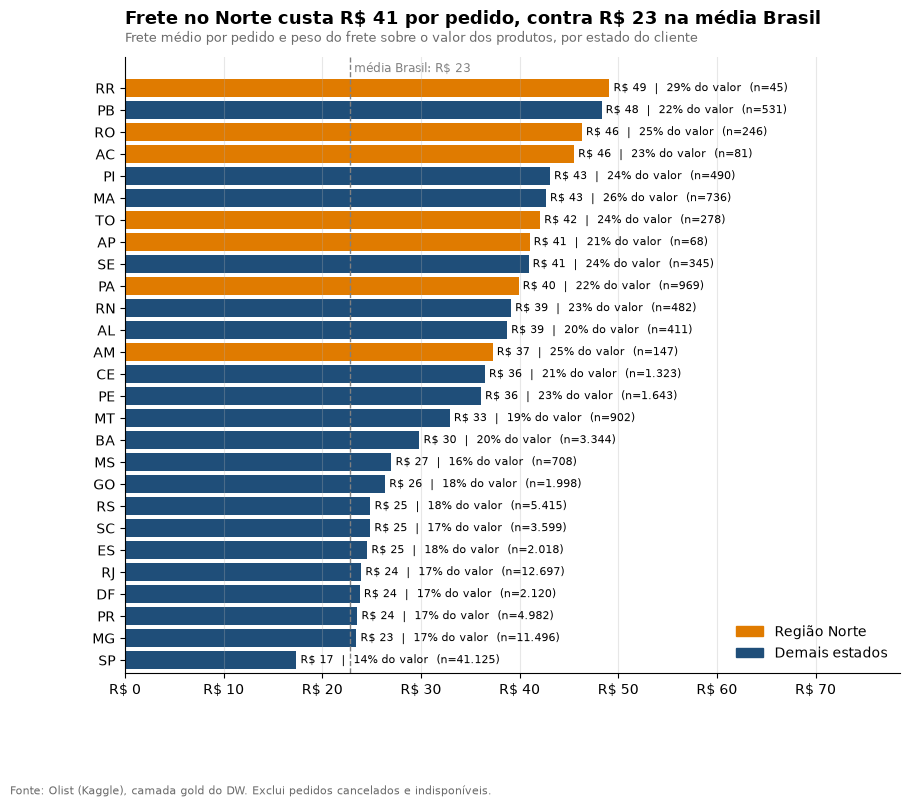

,uf,frete_medio,frete_pct_valor,pedidos
26,RR,49.100667,28.548965,45
25,PB,48.303898,22.328245,531
24,RO,46.309472,24.748477,246
23,AC,45.515432,23.066768,81
22,PI,43.072204,24.354210,490
21,MA,42.658071,26.318982,736
20,TO,42.071439,23.672001,278
19,AP,41.007353,20.694953,68
18,SE,40.902812,23.949875,345
17,PA,39.896202,21.619046,969


In [18]:
frete_uf = q("""
SELECT customer_state AS uf,
       avg(freight_value) AS frete_medio,
       sum(freight_value) / sum(order_value) * 100 AS frete_pct_valor,
       count(*) AS pedidos
FROM gold.fact_orders
WHERE is_valid_sale AND freight_value IS NOT NULL
GROUP BY 1
ORDER BY frete_medio
""")
frete_uf[["frete_medio", "frete_pct_valor"]] = frete_uf[["frete_medio", "frete_pct_valor"]].astype(float)

# Médias ponderadas pelo número de pedidos
media_frete_brasil = (frete_uf["frete_medio"] * frete_uf["pedidos"]).sum() / frete_uf["pedidos"].sum()
norte = frete_uf[frete_uf["uf"].isin(ESTADOS_NORTE)]
frete_norte = (norte["frete_medio"] * norte["pedidos"]).sum() / norte["pedidos"].sum()

cores = [COR_DESTAQUE if uf in ESTADOS_NORTE else COR for uf in frete_uf["uf"]]
rotulos = [f"R$ {br(v, 0)}  |  {br(p, 0)}% do valor  (n={br(n, 0)})"
           for v, p, n in zip(frete_uf["frete_medio"], frete_uf["frete_pct_valor"], frete_uf["pedidos"])]

fig, ax = plt.subplots(figsize=(10, 8))
barras = ax.barh(frete_uf["uf"], frete_uf["frete_medio"], color=cores)
ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
ax.axvline(media_frete_brasil, color="gray", linestyle="--", linewidth=1)
ax.text(media_frete_brasil, len(frete_uf) - 0.4, f" média Brasil: R$ {br(media_frete_brasil, 0)}",
        color="gray", fontsize=8.5, va="bottom")
ax.set_xlim(0, frete_uf["frete_medio"].max() * 1.6)
ax.set_ylim(-0.6, len(frete_uf) + 0.4)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", alpha=0.3)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R$ {br(v, 0)}"))
ax.legend(handles=[Patch(color=COR_DESTAQUE, label="Região Norte"), Patch(color=COR, label="Demais estados")],
          loc="lower right", frameon=False)

titulo(ax,
       f"Frete no Norte custa R$ {br(frete_norte, 0)} por pedido, contra R$ {br(media_frete_brasil, 0)} na média Brasil",
       "Frete médio por pedido e peso do frete sobre o valor dos produtos, por estado do cliente")
rodape(fig, "Exclui pedidos cancelados e indisponíveis.")
salvar(fig, "t4_frete_por_estado")
plt.show()

frete_uf.sort_values("frete_medio", ascending=False)

**Conclusão:** o frete médio por pedido vai de R$ 17 em SP a R$ 49 em RR. No Norte, a média é de R$ 41, 81% acima da média Brasil (R$ 23), e o frete chega a representar 28,5% do valor dos produtos em RR, contra 13,8% em SP. O Nordeste também paga caro (PB tem o 2º maior frete). Um frete que custa um quarto do pedido é uma barreira de compra, e políticas como frete subsidiado ou vendedores regionais tendem a destravar a conversão nessas regiões.

## Tópico 5: Clientes e pagamentos
**Pergunta (a): qual a porcentagem de clientes que compraram mais de uma vez?**

- O cliente é identificado pelo `customer_unique_id`. O `customer_id` é gerado a cada pedido (regra #7).
- A tabela abaixo mostra o impacto de usar a chave errada.
- Apenas pedidos não cancelados e não indisponíveis.

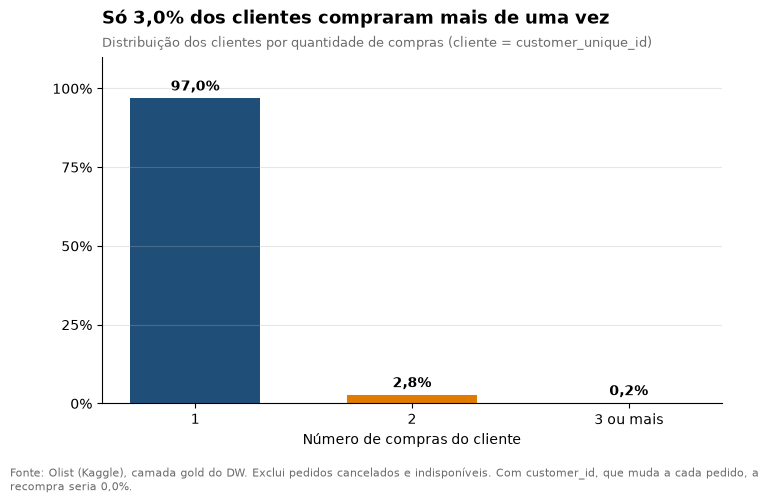

,chave,pct_recompra
0,customer_id (chave errada),0.00000
1,customer_unique_id (chave correta),3.04032


In [19]:
comparacao = q("""
SELECT 'customer_id (chave errada)' AS chave,
       100.0 * count(*) FILTER (WHERE pedidos > 1) / count(*) AS pct_recompra
FROM (SELECT customer_id, count(*) AS pedidos FROM gold.fact_orders WHERE is_valid_sale GROUP BY 1)
UNION ALL
SELECT 'customer_unique_id (chave correta)',
       100.0 * count(*) FILTER (WHERE pedidos > 1) / count(*)
FROM (SELECT customer_unique_id, count(*) AS pedidos FROM gold.fact_orders WHERE is_valid_sale GROUP BY 1)
""")
recompra = q("""
WITH compras AS (
    SELECT customer_unique_id, count(*) AS pedidos
    FROM gold.fact_orders
    WHERE is_valid_sale
    GROUP BY 1
)
SELECT CASE WHEN pedidos >= 3 THEN '3 ou mais' ELSE CAST(pedidos AS VARCHAR) END AS compras,
       count(*) AS clientes
FROM compras
GROUP BY 1
ORDER BY 1
""")
recompra["pct"] = recompra["clientes"] / recompra["clientes"].sum() * 100
pct_recompra = recompra.loc[recompra["compras"] != "1", "pct"].sum()
pct_chave_errada = comparacao.loc[comparacao["chave"].str.startswith("customer_id "), "pct_recompra"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(recompra["compras"], recompra["pct"], width=0.6,
                color=[COR if c == "1" else COR_DESTAQUE for c in recompra["compras"]])
ax.bar_label(barras, labels=[f"{br(p, 1)}%" for p in recompra["pct"]], padding=3, fontweight="bold")
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 25))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{br(v, 0)}%"))
ax.set_xlabel("Número de compras do cliente")

titulo(ax,
       f"Só {br(pct_recompra, 1)}% dos clientes compraram mais de uma vez",
       "Distribuição dos clientes por quantidade de compras (cliente = customer_unique_id)")
rodape(fig, f"Exclui pedidos cancelados e indisponíveis. Com customer_id, que muda a cada pedido, "
            f"a recompra seria {br(pct_chave_errada, 1)}%.")
salvar(fig, "t5_recompra")
plt.show()

comparacao

**Conclusão:** apenas 3,0% dos clientes compraram mais de uma vez. A base é quase toda de compra única, então retenção é a maior oportunidade de crescimento: ações de recompra (CRM, cupons pós-entrega) atuam sobre 97% dos clientes. A identificação correta do cliente é decisiva: usando o customer_id, que muda a cada pedido, a recompra apareceria como 0%.

## Tópico com maior afinidade

**Logística.** Trabalho como assistente de e-commerce na Bemol, atendendo o interior do Amazonas, onde boa parte das entregas depende de rios e igarapés e o período de seca pode travar a operação. Por isso o prazo e o frete definem a experiência do cliente aqui.

Os dados da Olist mostram esse padrão na Região Norte: os pedidos levam em média 22,5 dias para chegar, contra 12,5 dias no Brasil, 80% a mais (Tópico 2). O frete médio é de R$ 41 por pedido, contra R$ 23 no país, 81% mais caro (Tópico 4). O cliente do Norte espera quase o dobro e paga quase o dobro de frete, o que pesa ainda mais em produtos de médio e grande porte, que muitas vezes ficam caros demais para comprar de outros estados.